Please upload your PlayTennis CSV file.


Saving PlayTennis.csv to PlayTennis.csv

Uploaded file: PlayTennis.csv

PLAY TENNIS DATASET

First 5 Records:
    outlook  temp humidity  windy play
0     sunny   hot     high  False   no
1     sunny   hot     high   True   no
2  overcast   hot     high  False  yes
3     rainy  mild     high  False  yes
4     rainy  cool   normal  False  yes

Column Names:
['outlook', 'temp', 'humidity', 'windy', 'play']

Dataset Shape:
(14, 5)

Missing Values:
outlook     0
temp        0
humidity    0
windy       0
play        0
dtype: int64

Target Column:
play

Missing Values After Cleaning:
outlook     0
temp        0
humidity    0
windy       0
play        0
dtype: int64

Class Distribution:
play
yes    9
no     5
Name: count, dtype: int64

ATTRIBUTES
['outlook', 'temp', 'humidity', 'windy']

Number of Attributes:
4

CANDIDATE ELIMINATION RESULTS

Number of Positive Examples:
9

Number of Negative Examples:
5

MOST SPECIFIC HYPOTHESIS
outlook : ?
temp : ?
humidity : ?
windy : ?

MOST GENERAL HYPOT

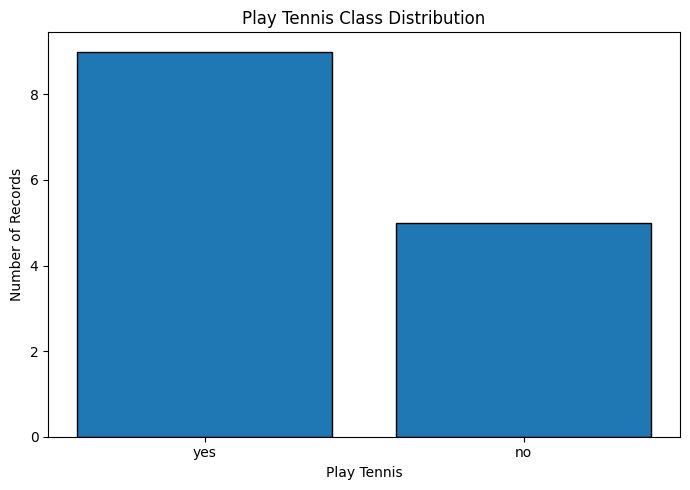

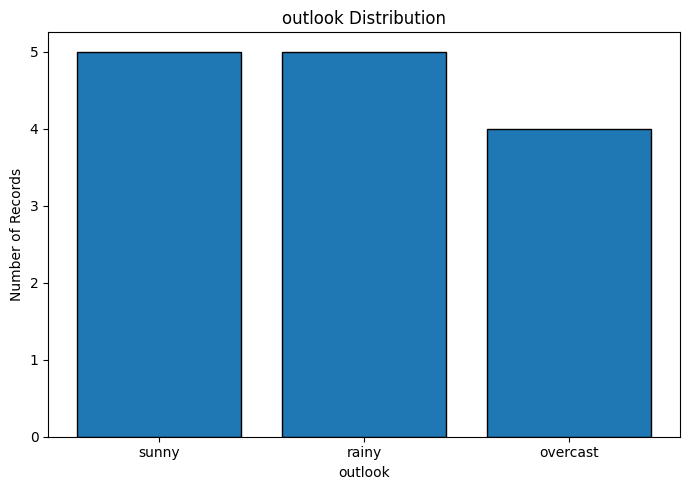

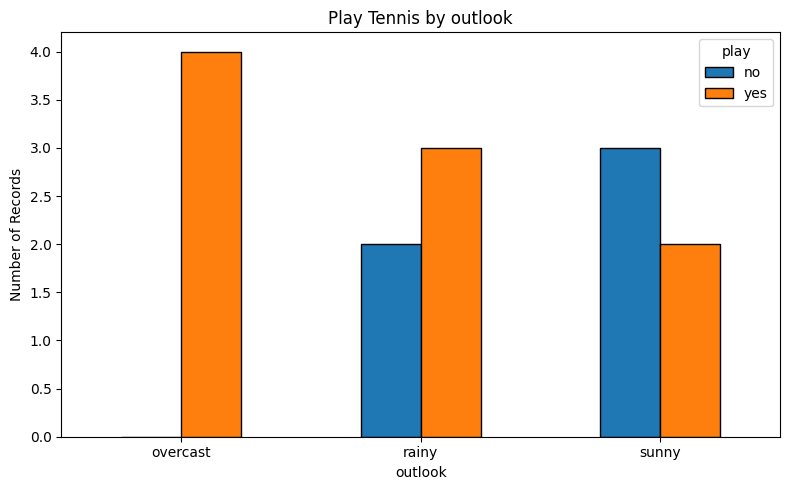

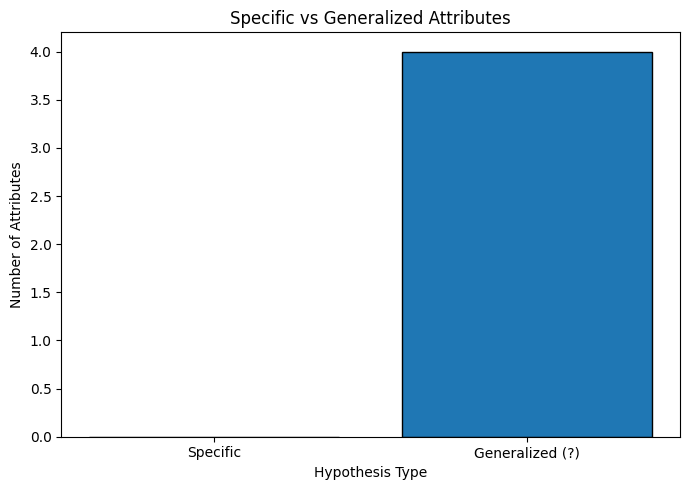


PROGRAM COMPLETED

Cleaned dataset saved as: Play_Tennis_Cleaned.csv

Candidate Elimination completed successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CANDIDATE ELIMINATION ALGORITHM
# PLAY TENNIS DATASET - GOOGLE COLAB
# ============================================================

# ------------------------------------------------------------
# STEP 1: IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files


# ------------------------------------------------------------
# STEP 2: UPLOAD DATASET
# ------------------------------------------------------------

print("Please upload your PlayTennis CSV file.")

uploaded = files.upload()

# Automatically get the uploaded filename
filename = list(uploaded.keys())[0]

print("\nUploaded file:", filename)


# ------------------------------------------------------------
# STEP 3: LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv(filename)

print("\n==============================================")
print("PLAY TENNIS DATASET")
print("==============================================")

print("\nFirst 5 Records:")
print(df.head())


# ------------------------------------------------------------
# STEP 4: CLEAN COLUMN NAMES
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for column in df.columns:

    if df[column].dtype == "object":

        df[column] = (
            df[column]
            .astype(str)
            .str.strip()
        )


print("\nColumn Names:")
print(df.columns.tolist())


# ------------------------------------------------------------
# STEP 5: DATASET INFORMATION
# ------------------------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())


# ------------------------------------------------------------
# STEP 6: IDENTIFY TARGET COLUMN
# ------------------------------------------------------------

# The PlayTennis dataset normally has the target column "Play".
# This code also handles "play" if the capitalization is different.

target_column = None

for column in df.columns:

    if column.lower() == "play":

        target_column = column

        break


if target_column is None:

    print("\nTarget column 'Play' was not found.")

    print("Available columns:")
    print(df.columns.tolist())

    raise ValueError(
        "Please check the target column name."
    )


print("\nTarget Column:")
print(target_column)


# ------------------------------------------------------------
# STEP 7: HANDLE MISSING VALUES
# ------------------------------------------------------------

for column in df.columns:

    if df[column].isnull().any():

        df[column] = df[column].fillna(
            df[column].mode()[0]
        )


print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


# ------------------------------------------------------------
# STEP 8: CLASS DISTRIBUTION
# ------------------------------------------------------------

print("\nClass Distribution:")

print(
    df[target_column].value_counts()
)


# ------------------------------------------------------------
# STEP 9: PREPARE X AND Y
# ------------------------------------------------------------

# All columns except target are attributes

attributes = [
    column
    for column in df.columns
    if column != target_column
]

X = df[attributes].values

y = df[target_column].values


print("\n==============================================")
print("ATTRIBUTES")
print("==============================================")

print(attributes)

print("\nNumber of Attributes:")
print(len(attributes))


# ------------------------------------------------------------
# STEP 10: INITIAL SPECIFIC AND GENERAL HYPOTHESIS
# ------------------------------------------------------------

# S = Most Specific Hypothesis

S = ["∅"] * len(attributes)


# G = Most General Hypothesis

G = [
    ["?"] * len(attributes)
]


# ------------------------------------------------------------
# STEP 11: COVERS FUNCTION
# ------------------------------------------------------------

def covers(h, x):

    for i in range(len(h)):

        # ? means any value is accepted
        if h[i] == "?":

            continue

        # Empty value does not cover anything
        if h[i] == "∅":

            return False

        # Values must match
        if h[i] != x[i]:

            return False

    return True


# ------------------------------------------------------------
# STEP 12: CANDIDATE ELIMINATION ALGORITHM
# ------------------------------------------------------------

positive_count = 0
negative_count = 0


for x, label in zip(X, y):

    label = str(label).strip().lower()


    # ========================================================
    # POSITIVE EXAMPLE
    # ========================================================

    if label == "yes":

        positive_count += 1

        # Remove G hypotheses that do not cover
        # the positive example

        G = [
            g
            for g in G
            if covers(g, x)
        ]


        # First positive example

        if S == ["∅"] * len(attributes):

            S = list(x)


        else:

            # Generalize S

            for i in range(len(attributes)):

                if S[i] != x[i]:

                    S[i] = "?"


    # ========================================================
    # NEGATIVE EXAMPLE
    # ========================================================

    elif label == "no":

        negative_count += 1

        new_G = []


        for g in G:

            # If G covers negative example
            if covers(g, x):

                # Specialize G

                for i in range(len(attributes)):

                    if g[i] == "?":

                        # Use S value for specialization
                        if (
                            S[i] != "?"
                            and S[i] != "∅"
                        ):

                            h = g.copy()

                            h[i] = S[i]


                            if h not in new_G:

                                new_G.append(h)


            else:

                new_G.append(g)


        G = new_G


# ------------------------------------------------------------
# STEP 13: DISPLAY RESULTS
# ------------------------------------------------------------

print("\n==============================================")
print("CANDIDATE ELIMINATION RESULTS")
print("==============================================")


print("\nNumber of Positive Examples:")

print(positive_count)


print("\nNumber of Negative Examples:")

print(negative_count)


# ------------------------------------------------------------
# STEP 14: MOST SPECIFIC HYPOTHESIS
# ------------------------------------------------------------

print("\n==============================================")
print("MOST SPECIFIC HYPOTHESIS")
print("==============================================")


for attribute, value in zip(attributes, S):

    print(
        attribute,
        ":",
        value
    )


# ------------------------------------------------------------
# STEP 15: MOST GENERAL HYPOTHESES
# ------------------------------------------------------------

print("\n==============================================")
print("MOST GENERAL HYPOTHESES")
print("==============================================")


if len(G) == 0:

    print("Empty")

else:

    for index, g in enumerate(G):

        print("\nG", index + 1)

        for attribute, value in zip(attributes, g):

            print(
                attribute,
                ":",
                value
            )


# ------------------------------------------------------------
# STEP 16: VERSION SPACE
# ------------------------------------------------------------

print("\n==============================================")
print("FINAL VERSION SPACE")
print("==============================================")


print("\nSpecific Boundary (S):")

print(S)


print("\nGeneral Boundary (G):")


if len(G) == 0:

    print("Empty")

else:

    for g in G:

        print(g)


# ============================================================
# GRAPH 1: CLASS DISTRIBUTION
# ============================================================

class_counts = df[target_column].value_counts()


plt.figure(figsize=(7, 5))


plt.bar(
    class_counts.index,
    class_counts.values,
    edgecolor="black"
)


plt.title(
    "Play Tennis Class Distribution"
)


plt.xlabel(
    "Play Tennis"
)


plt.ylabel(
    "Number of Records"
)


plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 2: ATTRIBUTE DISTRIBUTION
# ============================================================

# Select the first attribute automatically
first_attribute = attributes[0]

attribute_counts = (
    df[first_attribute]
    .value_counts()
)


plt.figure(figsize=(7, 5))


plt.bar(
    attribute_counts.index,
    attribute_counts.values,
    edgecolor="black"
)


plt.title(
    first_attribute + " Distribution"
)


plt.xlabel(
    first_attribute
)


plt.ylabel(
    "Number of Records"
)


plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 3: TARGET BY FIRST ATTRIBUTE
# ============================================================

cross_table = pd.crosstab(
    df[first_attribute],
    df[target_column]
)


cross_table.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)


plt.title(
    "Play Tennis by " + first_attribute
)


plt.xlabel(
    first_attribute
)


plt.ylabel(
    "Number of Records"
)


plt.xticks(
    rotation=0
)


plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 4: SPECIFIC VS GENERALIZED ATTRIBUTES
# ============================================================

specific_attributes = sum(
    1
    for value in S
    if value != "?"
)


generalized_attributes = sum(
    1
    for value in S
    if value == "?"
)


hypothesis_data = {
    "Specific": specific_attributes,
    "Generalized (?)": generalized_attributes
}


plt.figure(figsize=(7, 5))


plt.bar(
    hypothesis_data.keys(),
    hypothesis_data.values(),
    edgecolor="black"
)


plt.title(
    "Specific vs Generalized Attributes"
)


plt.xlabel(
    "Hypothesis Type"
)


plt.ylabel(
    "Number of Attributes"
)


plt.tight_layout()

plt.show()


# ============================================================
# STEP 17: SAVE CLEANED DATASET
# ============================================================

output_file = "Play_Tennis_Cleaned.csv"


df.to_csv(
    output_file,
    index=False
)


print("\n==============================================")
print("PROGRAM COMPLETED")
print("==============================================")


print(
    "\nCleaned dataset saved as:",
    output_file
)


print(
    "\nCandidate Elimination completed successfully."
)


# ------------------------------------------------------------
# STEP 18: DOWNLOAD CLEANED DATASET
# ------------------------------------------------------------

files.download(output_file)